In [1]:
%pip install -q "transformers==4.57.1" "accelerate==1.11.0" pillow pandas

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import json
import unicodedata
from pathlib import Path
import torch
import urllib.request
import os
import pandas as pd
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from transformers import AutoProcessor, GenerationConfig, Qwen3VLForConditionalGeneration

In [ ]:
font_path = "DejaVuSans.ttf"
if not os.path.exists(font_path):
    url = "https://raw.githubusercontent.com/matplotlib/matplotlib/main/lib/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf"
    urllib.request.urlretrieve(url, font_path)

In [5]:
ROOT = Path("/content/drive/MyDrive/MLLM/vision_to_llm")
DATA = ROOT / "data/day3"
OUTPUTS = ROOT / "outputs"
MAX_NEW_TOKENS = 64
MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"

DATA.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

processor = AutoProcessor.from_pretrained(MODEL_ID, use_fast=False)

model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    dtype=dtype,
    device_map="cuda:0",
    attn_implementation="sdpa"
).eval()

GEN = GenerationConfig(
    max_new_tokens=MAX_NEW_TOKENS,
    do_sample=False,
    bos_token_id=model.generation_config.bos_token_id,
    eos_token_id=model.generation_config.eos_token_id,
    pad_token_id=processor.tokenizer.pad_token_id
)

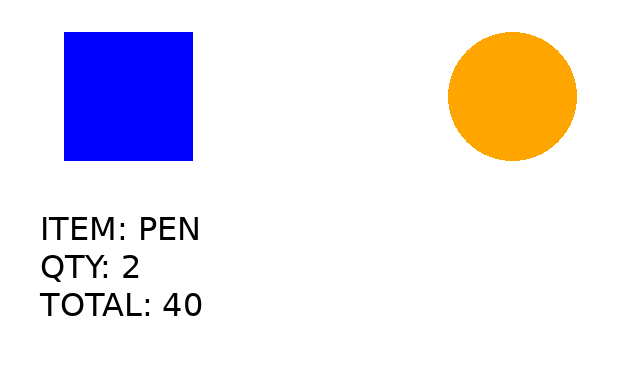

In [ ]:
DATA = Path(".") 
samples = [
    dict(id="dev", split="dev", side="left",
         square="blue", circle="orange",
         item="PEN", quantity=2, total=40),

    dict(id="eval_1", split="eval", side="right",
         square="green", circle="red",
         item="MUG", quantity=3, total=750),

    dict(id="eval_2", split="eval", side="left",
         square="red", circle="blue",
         item="BOOK", quantity=1, total=320)
]

font = ImageFont.truetype(font_path, 32)
boxes = {
    "left": (64, 32, 192, 160),
    "right": (448, 32, 576, 160)
}

for s in samples:
    s["circle_side"] = "right" if s["side"] == "left" else "left"
    s["text"] = (
        f"ITEM: {s['item']}\n"
        f"QTY: {s['quantity']}\n"
        f"TOTAL: {s['total']}"
    )

    image = Image.new("RGB", (640, 384), "white")
    draw = ImageDraw.Draw(image)

    draw.rectangle(boxes[s["side"]], fill=s["square"])
    draw.ellipse(boxes[s["circle_side"]], fill=s["circle"])
    draw.multiline_text(
        (40, 210), s["text"],
        font=font, fill="black", spacing=8,
    )

    s["path"] = str(DATA / f"{s['id']}.png")
    image.save(s["path"])


display(Image.open(samples[0]["path"]))

**inference pipeline**

In [11]:
@torch.inference_mode()
def answer_image(image_path, question):
    with Image.open(image_path) as source:
        image = source.convert("RGB")
    
    message = [{
        "role" : "user",
        "content" : [
            {"type" : "image"},
            {"type" : "text", "text" : question}
        ]
    }]
    
    prompt = processor.apply_chat_template(
        message, tokenize=False, add_generation_prompt=True
    )
    
    batch = processor(
        text=[prompt],
        images=[image],
        do_resize=False,
        return_tensors="pt",
    ).to(model.device)
    
    output = model.generate(
        **batch,
        generation_config=GEN,
        use_model_defaults=False,
        do_sample=False
    )
    
    new_ids = output[:, batch["input_ids"].shape[1]:]

    answer = processor.batch_decode(
        new_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]
    
    return {
        "answer": answer,
        "new_tokens": new_ids.shape[1],
    }

**Questions and references**

In [15]:
def task_examples(s):
    right_shape = "square" if s["side"] == "right" else "circle"
    
    return [
        (
            "vqa",
            "What color is the square? Answer in English with one word.",
            [s["square"]]
        ),
        (
            "vqa",
            "Which shape is on the right? Answer with one word.",
            [right_shape]
        ),
        (
            "vqa",
            "Is the circle left or right of the square? Answer left or right.",
            [s["circle_side"]]
        ),
        (
            "ocr",
            "Transcribe all printed text exactly. Output only the text.",
            [s["text"]]
        ),
        (
            "json",
            "Read the printed fields. Return only a JSON object with "
            "exactly these keys: item (string), quantity (integer), "
            "total (integer). No markdown or explanation.",
            {
                "item": s["item"],
                "quantity": s["quantity"],
                "total": s["total"]
            }
        ),
    ]

In [13]:
def normalize(text):
    text = unicodedata.normalize("NFKC", text)
    return " ".join(text.casefold().split())

def score(task, answer, reference):
    if task != "json":
        prediction = normalize(answer)

        if task == "vqa":
            prediction = prediction.strip(".!?")
        
        return {
            "correct": prediction in [normalize(r) for r in reference]
        }
    
    try:
        obj = json.loads(answer)
    except json.JSONDecodeError:
        return {
            "correct": False,
            "json_valid": False,
            "schema_valid": False,
        }
    
    schema = (
        isinstance(obj, dict)
        and set(obj) == set(reference)
        and isinstance(obj["item"], str)
        and type(obj["quantity"]) is int
        and type(obj["total"]) is int
    )
    
    correct = (
        schema
        and normalize(obj["item"]) == normalize(reference["item"])
        and obj["quantity"] == reference["quantity"]
        and obj["total"] == reference["total"]
    )
    
    return {
        "correct": correct,
        "json_valid": True,
        "schema_valid": schema
    }

In [16]:
def run_split(split):
    rows = []

    for s in samples:
        if s["split"] != split:
            continue

        for task, question, reference in task_examples(s):
            result = answer_image(s["path"], question)

            rows.append({
                "sample_id": s["id"],
                "split": split,
                "model": MODEL_ID,
                "task": task,
                "question": question,
                "reference": reference,
                **result,
                **score(task, result["answer"], reference)
            })

    return pd.DataFrame(rows)


dev_df = run_split("dev")
display(dev_df[["task", "reference", "answer", "correct"]])

,task,reference,answer,correct
0,vqa,[blue],blue,True
1,vqa,[circle],circle,True
2,vqa,[right],right,True
3,ocr,[ITEM: PEN\nQTY: 2\nTOTAL: 40],ITEM: PEN\nQTY: 2\nTOTAL: 40,True
4,json,"{'item': 'PEN', 'quantity': 2, 'total': 40}","```json\n{\n ""item"": ""PEN"",\n ""quantity"": 2,...",False


In [17]:
eval_df = run_split("eval")

display(
    eval_df[["sample_id", "task", "reference", "answer", "correct"]]
)

summary = (
    eval_df.groupby("task")
    .agg(
        examples=("correct", "size"),
        success_pct=("correct", "mean"),
    ).reset_index()
)

summary["success_pct"] *= 100
display(summary.round(1))
json_rows = eval_df[eval_df["task"] == "json"]

print("JSON parse success %:",
      round(100 * json_rows["json_valid"].astype(float).mean(), 1))

print("JSON schema success %:",
      round(100 * json_rows["schema_valid"].astype(float).mean(), 1))

dev_df.to_json(
    OUTPUTS / "day3_dev_results.json",
    orient="records", force_ascii=False, indent=2
)

eval_df.to_json(
    OUTPUTS / "day3_eval_results.json",
    orient="records", force_ascii=False, indent=2
)

summary.to_csv(OUTPUTS / "day3_metrics.csv", index=False)

,sample_id,task,reference,answer,correct
0,eval_1,vqa,[green],green,True
1,eval_1,vqa,[square],square,True
2,eval_1,vqa,[left],left,True
3,eval_1,ocr,[ITEM: MUG\nQTY: 3\nTOTAL: 750],ITEM: MUG\nQTY: 3\nTOTAL: 750,True
4,eval_1,json,"{'item': 'MUG', 'quantity': 3, 'total': 750}","```json\n{\n ""item"": ""MUG"",\n ""quantity"": 3,...",False
5,eval_2,vqa,[red],red,True
6,eval_2,vqa,[circle],circle,True
7,eval_2,vqa,[right],right,True
8,eval_2,ocr,[ITEM: BOOK\nQTY: 1\nTOTAL: 320],ITEM: BOOK\nQTY: 1\nTOTAL: 320,True
9,eval_2,json,"{'item': 'BOOK', 'quantity': 1, 'total': 320}","```json\n{\n ""item"": ""BOOK"",\n ""quantity"": 1...",False


,task,examples,success_pct
0,json,2,0.0
1,ocr,2,100.0
2,vqa,6,100.0


JSON parse success %: 0.0
JSON schema success %: 0.0
